In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, r2_score

df = pd.read_csv("cleaned_air_quality.csv")
features = ['CO AQI Value','Ozone AQI Value','NO2 AQI Value','PM2.5 AQI Value']
X_scaled = StandardScaler().fit_transform(df[features])


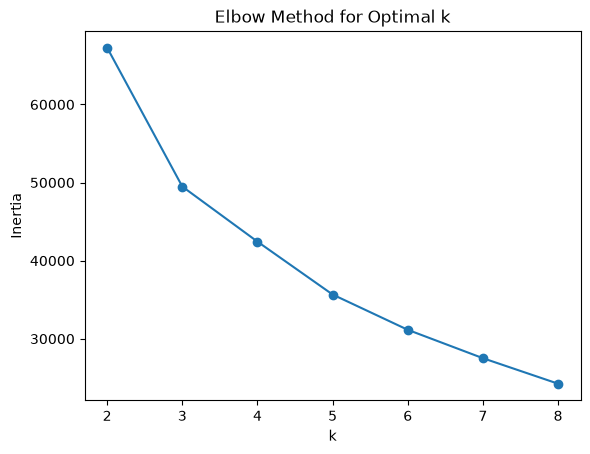

In [2]:
from sklearn.cluster import KMeans

inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_
            for k in range(2, 9)]
plt.plot(range(2,9), inertias, marker='o')
plt.xlabel("k"); plt.ylabel("Inertia"); plt.title("Elbow Method for Optimal k")
plt.show()


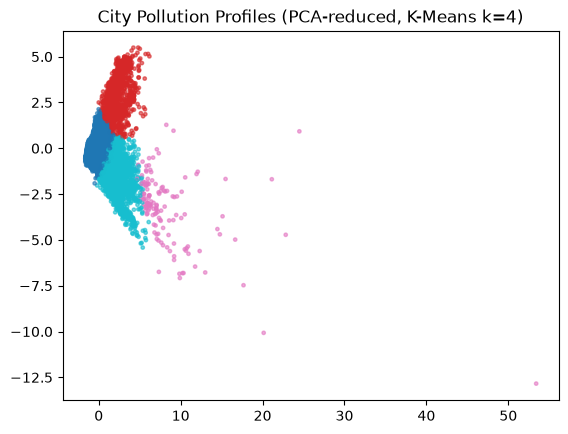

In [3]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['pollution_cluster'] = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)
plt.scatter(coords[:,0], coords[:,1], c=df['pollution_cluster'], cmap='tab10', s=6, alpha=0.6)
plt.title("City Pollution Profiles (PCA-reduced, K-Means k=4)")
plt.show()

df[['Country','City','pollution_cluster']].to_csv("cluster_labels.csv", index=False)


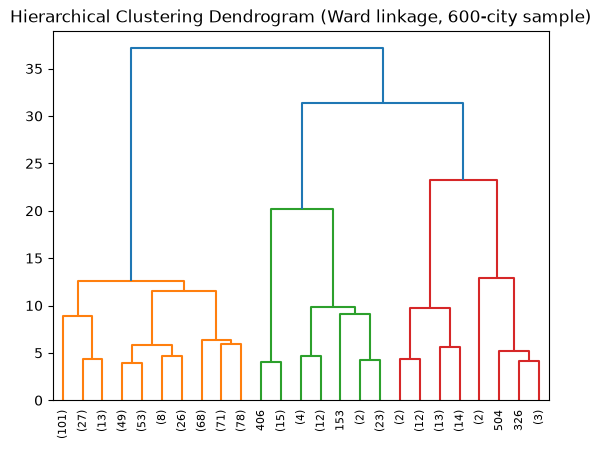

In [4]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

sample_idx = df.sample(n=600, random_state=42).index
X_sample = StandardScaler().fit_transform(df.loc[sample_idx, features])

linked = linkage(X_sample, method='ward')
dendrogram(linked, truncate_mode='lastp', p=25, leaf_rotation=90, leaf_font_size=8)
plt.title("Hierarchical Clustering Dendrogram (Ward linkage, 600-city sample)")
plt.show()


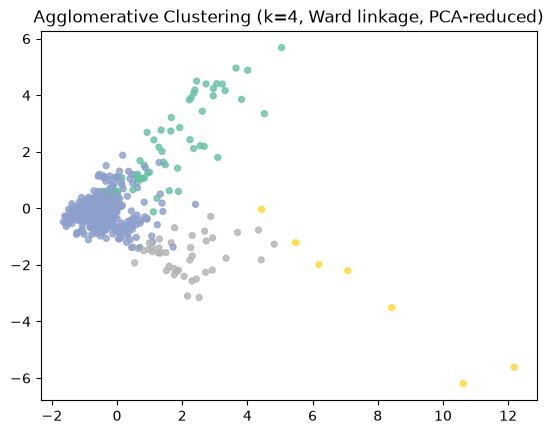

In [5]:
agglo = AgglomerativeClustering(n_clusters=4, linkage='ward')
agglo_labels = agglo.fit_predict(X_sample)

coords_s = PCA(n_components=2).fit_transform(X_sample)
plt.scatter(coords_s[:,0], coords_s[:,1], c=agglo_labels, cmap='Set2', s=18, alpha=0.8)
plt.title("Agglomerative Clustering (k=4, Ward linkage, PCA-reduced)")
plt.show()


In [6]:
from sklearn.linear_model import LogisticRegression

y = LabelEncoder().fit_transform(df['AQI Category'])
X_train, X_test, y_train, y_test = train_test_split(
    df[features], y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)


In [7]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_s, y_train)
y_pred_lr = logreg.predict(X_test_s)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))


Accuracy: 0.9422544214787982
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      1988
           1       0.97      0.87      0.92        38
           2       0.94      0.96      0.95      1846
           3       0.89      0.97      0.93       446
           4       0.91      0.83      0.87       318
           5       0.83      0.61      0.71        57

    accuracy                           0.94      4693
   macro avg       0.92      0.86      0.89      4693
weighted avg       0.94      0.94      0.94      4693



In [8]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=200, random_state=42)
clf.fit(X_train, y_train)          # Note: raw (unscaled) features -- RF is scale-invariant
y_pred_rf = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, digits=4))
print(confusion_matrix(y_test, y_pred_rf))


Accuracy: 0.9987215001065417
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1988
           1     0.9444    0.8947    0.9189        38
           2     1.0000    1.0000    1.0000      1846
           3     1.0000    1.0000    1.0000       446
           4     1.0000    1.0000    1.0000       318
           5     0.9322    0.9649    0.9483        57

    accuracy                         0.9987      4693
   macro avg     0.9794    0.9766    0.9779      4693
weighted avg     0.9987    0.9987    0.9987      4693

[[1988    0    0    0    0    0]
 [   0   34    0    0    0    4]
 [   0    0 1846    0    0    0]
 [   0    0    0  446    0    0]
 [   0    0    0    0  318    0]
 [   0    2    0    0    0   55]]


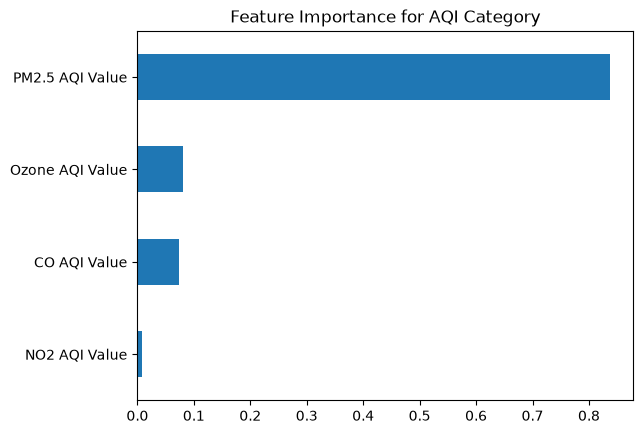

In [9]:
importances = pd.Series(clf.feature_importances_, index=features).sort_values()
importances.plot(kind='barh', title='Feature Importance for AQI Category')
plt.show()
importances.to_csv("feature_importance.csv")


In [10]:
from sklearn.model_selection import GridSearchCV, cross_val_score

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid,
                     cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)


Best params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best CV accuracy: 0.9990409547785594


In [11]:
cv_scores = cross_val_score(clf, df[features], y, cv=5, scoring='accuracy')
print("CV scores per fold:", np.round(cv_scores, 4))
print("Mean:", cv_scores.mean().round(4), "Std:", cv_scores.std().round(4))


CV scores per fold: [0.9987 0.9996 0.9989 0.9994 0.9998]
Mean: 0.9993 Std: 0.0004


In [12]:
from sklearn.svm import SVC

svm_sample = df.sample(n=3000, random_state=42)
Xs, ys = svm_sample[features], LabelEncoder().fit_transform(svm_sample['AQI Category'])
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.2, random_state=42, stratify=ys)

scaler_svm = StandardScaler().fit(Xs_train)
Xs_train_s, Xs_test_s = scaler_svm.transform(Xs_train), scaler_svm.transform(Xs_test)


In [13]:
svm_clf = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_clf.fit(Xs_train_s, ys_train)
ys_pred = svm_clf.predict(Xs_test_s)

print("Accuracy:", accuracy_score(ys_test, ys_pred))
print(classification_report(ys_test, ys_pred, digits=4))


Accuracy: 0.96
              precision    recall  f1-score   support

           0     0.9961    0.9656    0.9806       262
           1     1.0000    1.0000    1.0000         5
           2     0.9435    0.9915    0.9669       236
           3     0.8793    0.9808    0.9273        52
           4     0.9655    0.7568    0.8485        37
           5     0.8333    0.6250    0.7143         8

    accuracy                         0.9600       600
   macro avg     0.9363    0.8866    0.9063       600
weighted avg     0.9613    0.9600    0.9591       600



In [14]:
param_grid = {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto']}
grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid.fit(Xs_train_s, ys_train)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)


Best params: {'C': 10, 'gamma': 'auto'}
Best CV accuracy: 0.9545833333333333


In [16]:
# Option A: Live pull via World Bank API (needs internet — works in Colab/local Jupyter)
import requests
import pandas as pd

url = "https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD"
params = {"format": "json", "date": "2022", "per_page": "300"}
resp = requests.get(url, params=params).json()

gdp_df = pd.DataFrame([
    {"Country": rec["country"]["value"], "GDP_per_capita": rec["value"]}
    for rec in resp[1] if rec["value"] is not None
])
gdp_df.to_csv("world_bank_gdp_per_capita.csv", index=False)  # cache it once

In [19]:
country_avg = df[df['Country'] != 'Unknown'].groupby('Country')['AQI Value'].mean().reset_index()

rename_map = {
    "United States": "United States", "USA": "United States",
    "Russia": "Russian Federation",
    "South Korea": "Korea, Rep.",
    "North Korea": "Korea, Dem. People's Rep.",
    "Iran": "Iran, Islamic Rep.",
    "Egypt": "Egypt, Arab Rep.",
    "Turkey": "Turkiye",
    "Vietnam": "Viet Nam",
    "Venezuela": "Venezuela, RB",
    "Czech Republic": "Czechia",
    "Democratic Republic of the Congo": "Congo, Dem. Rep.",
    "Republic of the Congo": "Congo, Rep.",
    "Ivory Coast": "Cote d'Ivoire",
    "Syria": "Syrian Arab Republic",
    "Laos": "Lao PDR",
    "Slovakia": "Slovak Republic",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Brunei": "Brunei Darussalam",
    "Yemen": "Yemen, Rep.",
    "Bahamas": "Bahamas, The",
    "Gambia": "Gambia, The",
    "Micronesia": "Micronesia, Fed. Sts.",
    "Saint Lucia": "St. Lucia",
    "Saint Kitts and Nevis": "St. Kitts and Nevis",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Hong Kong": "Hong Kong SAR, China",
    "Macao": "Macao SAR, China",
}
country_avg['Country_std'] = country_avg['Country'].replace(rename_map)
gdp_df['Country_std'] = gdp_df['Country']  # World Bank names are already the target form

merged = country_avg.merge(gdp_df[['Country_std', 'GDP_per_capita']], on='Country_std', how='inner')

print(f"AQI countries: {len(country_avg)} | Matched to GDP data: {len(merged)}")
unmatched = set(country_avg['Country_std']) - set(gdp_df['Country_std'])
print("Still unmatched:", sorted(unmatched))

AQI countries: 175 | Matched to GDP data: 156
Still unmatched: ['Bolivia (Plurinational State of)', 'Congo', 'Cuba', "Côte d'Ivoire", 'Eritrea', 'Iran (Islamic Republic of)', 'Kingdom of Eswatini', "Lao People's Democratic Republic", 'Republic of Korea', 'Republic of Moldova', 'Republic of North Macedonia', 'Somalia', 'South Sudan', 'State of Palestine', 'United Kingdom of Great Britain and Northern Ireland', 'United Republic of Tanzania', 'United States of America', 'Venezuela (Bolivarian Republic of)', 'Yemen, Rep.']


In [22]:
rename_map.update({
    "Bolivia (Plurinational State of)": "Bolivia",
    "Congo": "Congo, Rep.",
    "Iran (Islamic Republic of)": "Iran, Islamic Rep.",
    "Kingdom of Eswatini": "Eswatini",
    "Lao People's Democratic Republic": "Lao PDR",
    "Republic of Korea": "Korea, Rep.",
    "Republic of Moldova": "Moldova",
    "Republic of North Macedonia": "North Macedonia",
    "State of Palestine": "West Bank and Gaza",
    "United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
    "United Republic of Tanzania": "Tanzania",
    "United States of America": "United States",
    "Venezuela (Bolivarian Republic of)": "Venezuela, RB",
})
# fix the curly-apostrophe mismatch separately (Côte d'Ivoire) —
# your data likely uses ’ (U+2019), World Bank uses '
country_avg['Country_std'] = country_avg['Country_std'].str.replace("\u2019", "'", regex=False)


In [23]:
country_avg['Country_std'] = country_avg['Country'].replace(rename_map)
country_avg['Country_std'] = country_avg['Country_std'].str.replace("\u2019", "'", regex=False)

merged = country_avg.merge(gdp_df[['Country_std', 'GDP_per_capita']], on='Country_std', how='inner')

print(f"AQI countries: {len(country_avg)} | Matched to GDP data: {len(merged)}")
unmatched = set(country_avg['Country_std']) - set(gdp_df['Country_std'])
print("Still unmatched:", sorted(unmatched))

AQI countries: 175 | Matched to GDP data: 169
Still unmatched: ['Cuba', "Côte d'Ivoire", 'Eritrea', 'Somalia', 'South Sudan', 'Yemen, Rep.']


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X_gdp = merged[['GDP_per_capita']]
y_gdp = merged['AQI Value']

Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    X_gdp, y_gdp, test_size=0.4 ,random_state=30
)

reg = LinearRegression().fit(Xg_train, yg_train)
y_pred = reg.predict(Xg_test)

print("R2:", r2_score(yg_test, y_pred))
print("MAE:", mean_absolute_error(yg_test, y_pred))
print("Coefficient:", reg.coef_[0])
print("Intercept:", reg.intercept_)

R2: -0.3512256574971784
MAE: 28.493308822131205
Coefficient: 1.3841300131229305e-06
Intercept: 78.61792167142337
